![rough map.png](<attachment:rough map.png>)
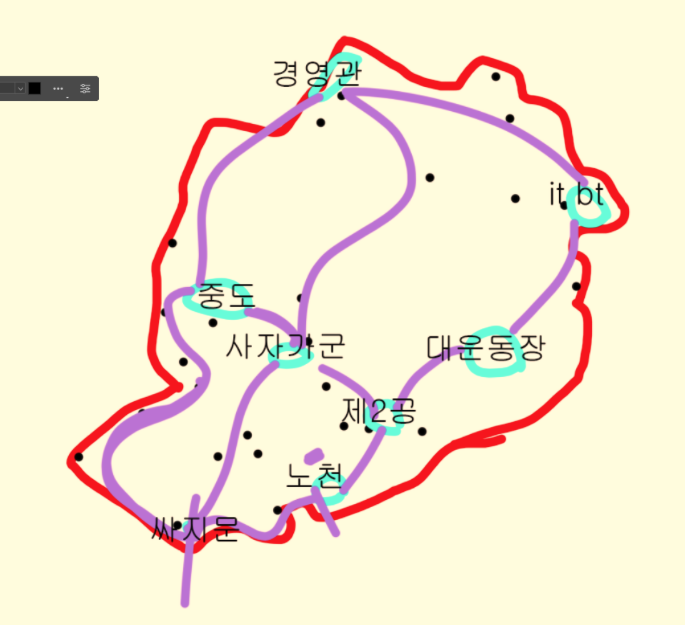

Shortest path from Aejeemun to ITBT : ['Aejeemun', 'Amphitheater', 'Engineering Building II', 'Sports Field', 'ITBT']


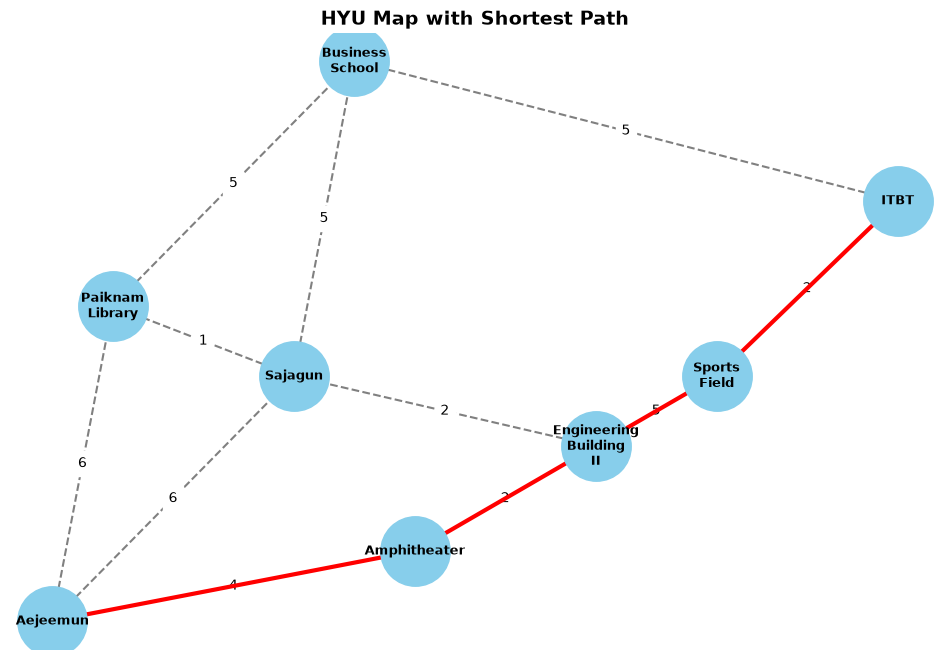

In [ ]:
import heapq
import matplotlib.pyplot as plt

# define the graph representing the map
graph = {
    'Aejeemun': {'Amphitheater': 4, 'Sajagun': 6, 'Paiknam Library' : 6},
    'Amphitheater': {'Aejeemun': 4, 'Engineering Building II': 2},
    'Engineering Building II': {'Amphitheater': 2, 'Sajagun': 2, 'Sports Field' : 5},
    'Sajagun': {'Aejeemun': 6, 'Engineering Building II': 2, 'Paiknam Library': 1, 'Business School' : 5},
    'Paiknam Library' : {'Aejeemun' : 6, 'Sajagun' : 1, 'Business School' : 5},
    'Sports Field' : {'Engineering Building II' : 5, 'ITBT' : 2},
    'ITBT' : {'Sports Field' : 2, 'Business School' : 5},
    'Business School' : {'Paiknam Library' : 5, 'Sajagun' : 5, 'ITBT' : 5}
}

def dijkstra(graph, start):
    distances = {node: float('inf') for node in graph} 
    distances[start] = 0  
    pq = [(0, start)]  

    while pq:  
        curr_dist, curr_node = heapq.heappop(pq)  

        if curr_dist > distances[curr_node]:  
            continue

        for neighbor, weight in graph[curr_node].items():  
            dist = curr_dist + weight  
            if dist < distances[neighbor]:  
                distances[neighbor] = dist
                heapq.heappush(pq, (dist, neighbor))

    return distances  

def shortest_path(graph, start, end):
    distances = dijkstra(graph, start)  
    path = [end]
    while end != start:  
        for neighbor, weight in graph[end].items():  
            if distances[end] == distances[neighbor] + weight:  
                path.append(neighbor)  
                end = neighbor  
                break  
    return path[::-1]  

# visualize the map and shortest path using only matplotlib
def visualize_map(graph, shortest):
    # set coordinates so that it matches the mental map (at the top)
    pos = {
        'Aejeemun': (2, 1),
        'Amphitheater': (5, 2),
        'Engineering Building II': (6.5, 3.5),
        'Sajagun': (4, 4.5),
        'Paiknam Library': (2.5, 5.5),
        'Sports Field': (7.5, 4.5),
        'ITBT': (9, 7),
        'Business School': (4.5, 9)
    }

    fig, ax = plt.subplots(figsize=(12, 8))
    drawn_edges = set() 

    for node, neighbors in graph.items():
        for neighbor, weight in neighbors.items():
            edge = frozenset([node, neighbor])
            if edge not in drawn_edges:
                drawn_edges.add(edge)
                x_values = [pos[node][0], pos[neighbor][0]]
                y_values = [pos[node][1], pos[neighbor][1]]
                
                ax.plot(x_values, y_values, color='gray', linestyle='--', zorder=1)
                
                mid_x = (x_values[0] + x_values[1]) / 2
                mid_y = (y_values[0] + y_values[1]) / 2
                ax.text(mid_x, mid_y, str(weight), color='black', fontsize=10, 
                        ha='center', va='center', backgroundcolor='white', zorder=2)

    for i in range(len(shortest) - 1):
        u = shortest[i]
        v = shortest[i + 1]
        x_values = [pos[u][0], pos[v][0]]
        y_values = [pos[u][1], pos[v][1]]
        ax.plot(x_values, y_values, color='red', linewidth=3, zorder=3)

    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=2500, color='skyblue', zorder=4)
        
        formatted_node_name = node.replace(' ', '\n')
        ax.text(x, y, formatted_node_name, fontsize=9, fontweight='bold', 
                ha='center', va='center', zorder=5)

    plt.title('HYU Map with Shortest Path', fontsize=14, fontweight='bold')
    plt.axis('off')  
    plt.show()

# 여기에 input 고고고
# example usage
start_node = 'Aejeemun'
end_node = 'ITBT'
shortest = shortest_path(graph, start_node, end_node)
print("Shortest path from", start_node, "to", end_node, ":", shortest)

# Visualize the map and shortest path
visualize_map(graph, shortest)